# Model Comparison

### Motivation
##### Three machine learning models: Random Forest (RF), Logistic Regression (LR), and Support Vector Machine (SVM) were developed to predict response to immunotherapy in patients with metastatic renal cell carcinoma (mRCC). Response was defined as partial or complete response, based on either a reduction in tumor size or progression-free survival of at least six months. Patients with progressive disease were classified as non-responders.

##### The three models are compared across cross-validation performance on the training data, feature importance, and external validation. Given the clinical context where failing to identify a potential responder carries greater consequence than a false positive, particular emphasis is placed on each model's sensitivity toward the responder class, rather than relying solely on AUROC or AUPRC as the primary performance criteria.

#### Data & Methods Note
##### Training (RNA-seq) and validation (microarray) data were generated on different platforms. Both datasets were normalized independently and converted to z-scores to place all features on a common relative scale. Thresholds for all three models were optimized using Youden's J index (maximizing sensitivity + specificity − 1), so all classification results reflect each model's best attainable operating point on the ROC curve.

In [1]:
## Loading required libraries

import pandas as pd
import numpy as np
from sklearn.base import clone
import matplotlib.pyplot as plt
from src.utils.plots import  plot_confusion_matrices, plot_coefficient_comparison
from src.utils.plots import plot_cv_metric_comparison, plot_roc_pr_comparison, performance_summary_table
import warnings
from typing import Literal
from typing import Literal
from scipy import stats
from sklearn.metrics import  roc_auc_score, confusion_matrix, average_precision_score, f1_score, recall_score, precision_score,  ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
import re



### Part A. Model Loading

### A1. Cross-validation results loading

In [2]:
# Loading Logistic regression cross validation results
lgm_cross_val_pred = pd.read_csv("results/model_eval/lgr_cross_val_predictions.csv")
lgm_cross_val_metrics = pd.read_csv("results/model_eval/lgr_cross_val_metrics.csv")
lgm_cross_val_coef = pd.read_csv("results/model_eval/lgr_cross_val_coef.csv")


# Random Forest cross validation results
rf_cross_val_pred = pd.read_csv("results/model_eval/rf_cross_val_predictions.csv")
rf_cross_val_metrics = pd.read_csv("results/model_eval/rf_cross_val_metrics.csv")
rf_cross_val_coef = pd.read_csv("results/model_eval/rf_cross_val_coef.csv")


# Support Vector Machine cross validation results
svm_cross_val_pred = pd.read_csv("results/model_eval/svm_cross_val_predictions.csv")
svm_cross_val_metrics = pd.read_csv("results/model_eval/svm_cross_val_metrics.csv")
svm_cross_val_coef = pd.read_csv("results/model_eval/svm_cross_val_coef.csv")


### A2. External validation results loading

In [3]:
# Loading Logistic regression external vaildation results

lgm_ext_pred = pd.read_csv("results/model_eval/lrm_external_predictions.csv")
lgm_ext_met = pd.read_csv("results/model_eval/lrm_external_metrics.csv")

# Loading Logistic regression external validation results
rf_ext_pred = pd.read_csv("results/model_eval/rf_external_predictions.csv")
rf_ext_met = pd.read_csv("results/model_eval/rf_external_metrics.csv")

# Loading Logistic regression external validation results
svm_ext_pred = pd.read_csv("results/model_eval/svm_external_predictions.csv")
svm_ext_met = pd.read_csv("results/model_eval/svm_external_metrics.csv")



### Part B. Cross-Validation Metric Comparison (Training Cohort)

##### Three classifiers, Random Forest (RF), Logistic Regression (LR), and Support Vector Machine (SVM) were evaluated using 5-fold cross-validation on the training cohort (35 responders, 68 non-responders). Performance was modest across all models, with median AUROC around  0.48 for RF, 0.51 for LR and 0.54 for SVM. The high fold-to-fold variability seen across all metrics is expected given the small cohort size, each fold trains on roughly 70–80 patients with fewer than 30 responders available to learn from. RF and SVM showed higher specificity (0.79 and 0.86) but low sensitivity (0.14 and 0.29), while LR achieved a better balance with median sensitivity of 0.43 and the highest F1 (0.40). Importantly, the final models evaluated on external data were trained on the full 103-patient training set, not the smaller fold subsets used in CV. 

##### Key message: CV performance was modest and variable, driven largely by small fold sizes rather than an absence of signal. LR offered the best sensitivity–specificity balance. These estimates are directional and should not be taken as the final generalization performance of the models.s

(<Figure size 2400x600 with 5 Axes>,
 array([<Axes: title={'center': 'AUROC'}, ylabel='AUROC'>,
        <Axes: title={'center': 'AUPRC'}, ylabel='AUPRC'>,
        <Axes: title={'center': 'Sensitivity'}, ylabel='Sensitivity'>,
        <Axes: title={'center': 'Specificity'}, ylabel='Specificity'>,
        <Axes: title={'center': 'F1 Score'}, ylabel='F1 Score'>],
       dtype=object))

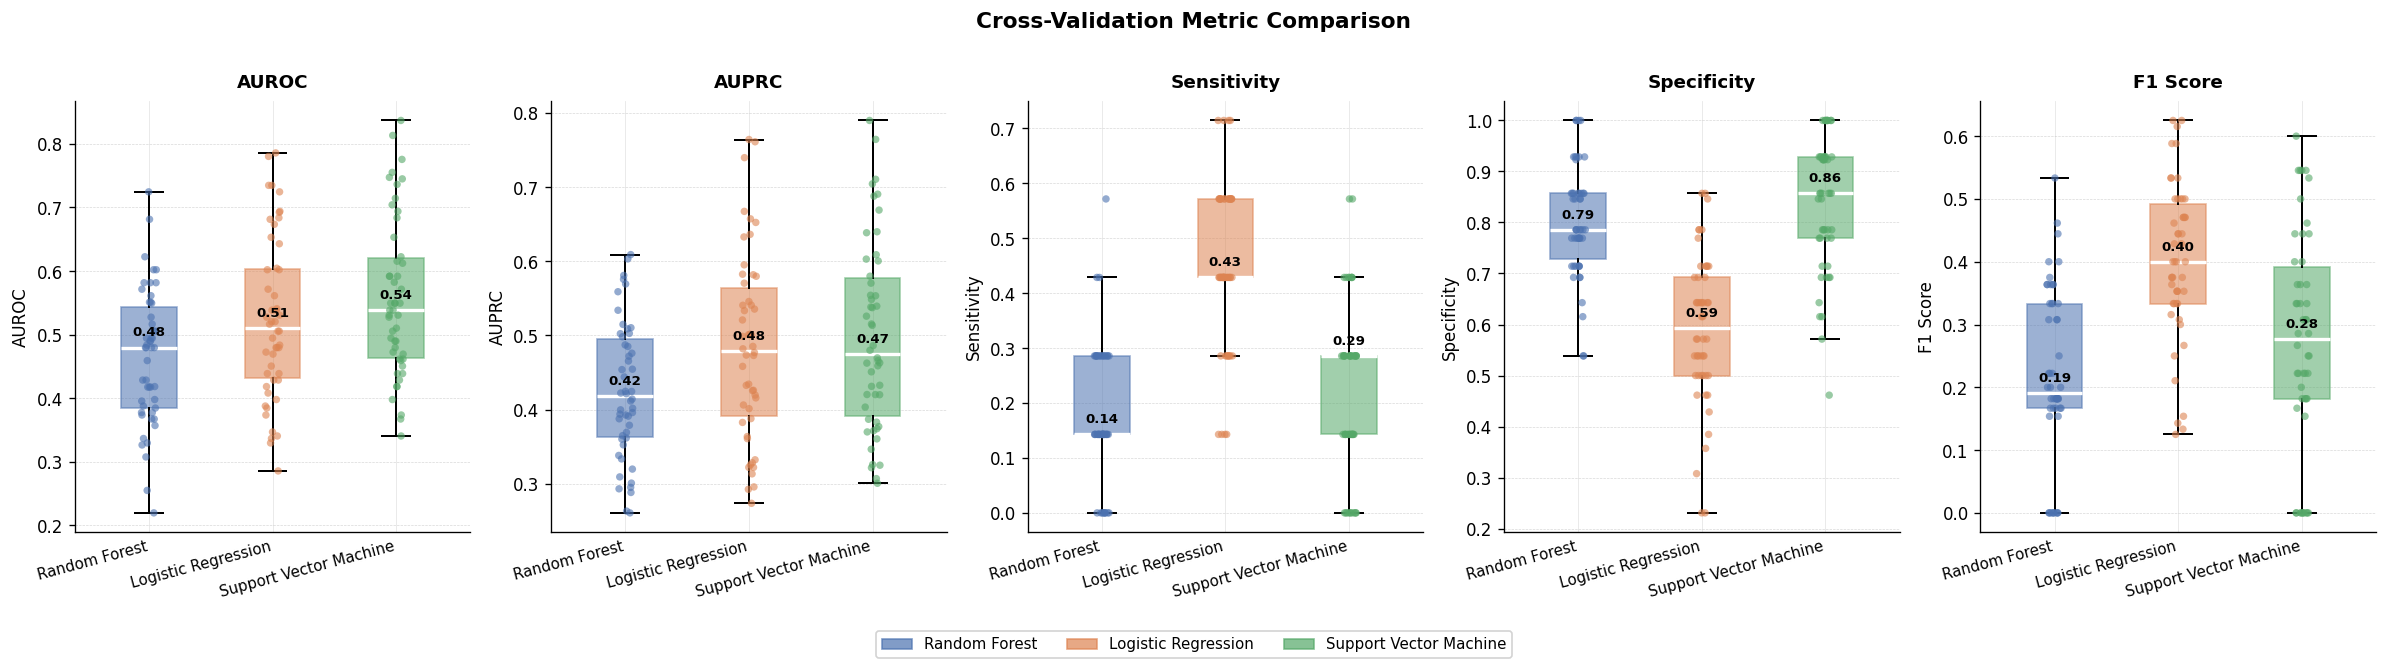

In [4]:
# Comparing cross-validation results

model = [ {"model_name": "Random Forest", "data": rf_cross_val_metrics},
          {"model_name": "Logistic Regression", "data": lgm_cross_val_metrics}, 
          {"model_name": "Support Vector Machine", "data": svm_cross_val_metrics}]

metrics=["AUROC", "AUPRC", "Sensitivity", "Specificity", "F1_score"]

plot_cv_metric_comparison(models = model, metrics = metrics )

### Part C. Feature Coefficient Comparison Across Models

#####  BAP1 and PBRM1 were the dominant predictors in both linear models, BAP1 carried the largest odds ratio in LR (2.24) and the highest coefficient in SVM (1.03), with PBRM1 second in both. This is consistent with their established roles as chromatin remodeling tumor suppressors in ccRCC and their reported association with immunotherapy response. Immune microenvironment features myeloid inflammation, T-effector, and stroma also contributed positive signal. Random Forest distributed importance more evenly across all features, with cell cycle and FAO/AMPK topping the list (0.13 and 0.11 ) and BAP1 ranking last (0.01), reflecting how tree ensembles handle correlated predictors rather than a genuine biological disagreement with the linear models.

#### Key message: BAP1 and PBRM1 mutations are the strongest and most consistent predictors across parametric models, in line with published biology. Immune signature features add complementary signal.

(<Figure size 1800x835.2 with 3 Axes>,
 array([<Axes: title={'center': 'Logistic Regression'}, xlabel='Odds Ratio (log scale)'>,
        <Axes: title={'center': 'SVM'}, xlabel='Coefficient'>,
        <Axes: title={'center': 'Random Forest'}, xlabel='Feature Importance'>],
       dtype=object))

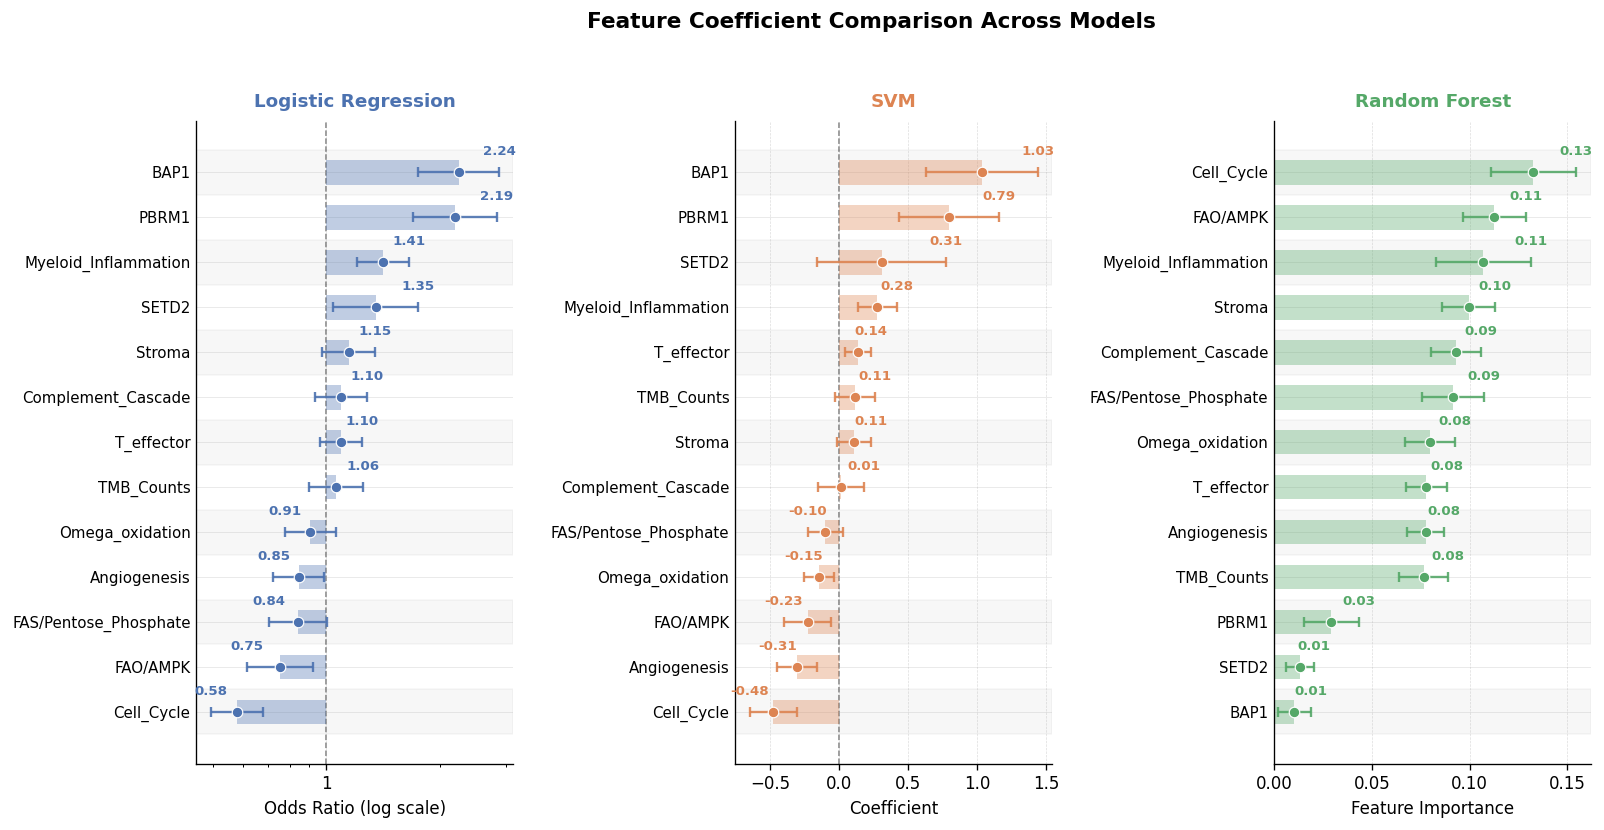

In [5]:


plot_coefficient_comparison(
    models=[
        {"model_name": "Logistic Regression", "data": lgm_cross_val_coef,
         "mode": "odds_ratio"},
        {"model_name": "SVM",                 "data": svm_cross_val_coef,
         "mode": "coefficient"},
        {"model_name": "Random Forest",        "data": rf_cross_val_coef,
         "mode": "importance"},
    ],

    strip_prefixes=True,
    top_n=15,           
)

### Part C1. External Validation ROC and PR Curves

##### On the independent validation cohort (9 responders, 19 non-responders; prevalence ~32%), SVM and LR models performed well above chance,however RF performed poorly. SVM led with AUROC 0.696 and AUPRC 0.577 against a no-skill baseline of 0.32, followed by LR (0.667 / 0.590) and RF (0.339/ 0.296). The jump from 5-fold CV (~0.54 AUROC) to external validation (~0.696) reflects two things: the final models were trained on the full training set rather than fold subsets, and z-score normalization appears to have effectively bridged the RNA-seq to microarray platform gap.
 

##### Key message: SVM and LR generalized to the external dataset despite the platform difference. RF underperformed compared to other models. The signal is real and appears platform transferable when z-score harmonization is applied.

(<Figure size 1560x720 with 2 Axes>,
 (<Axes: title={'center': 'ROC Curve'}, xlabel='False Positive Rate  (1 − Specificity)', ylabel='True Positive Rate  (Sensitivity)'>,
  <Axes: title={'center': 'Precision-Recall Curve'}, xlabel='Recall  (Sensitivity)', ylabel='Precision  (PPV)'>))

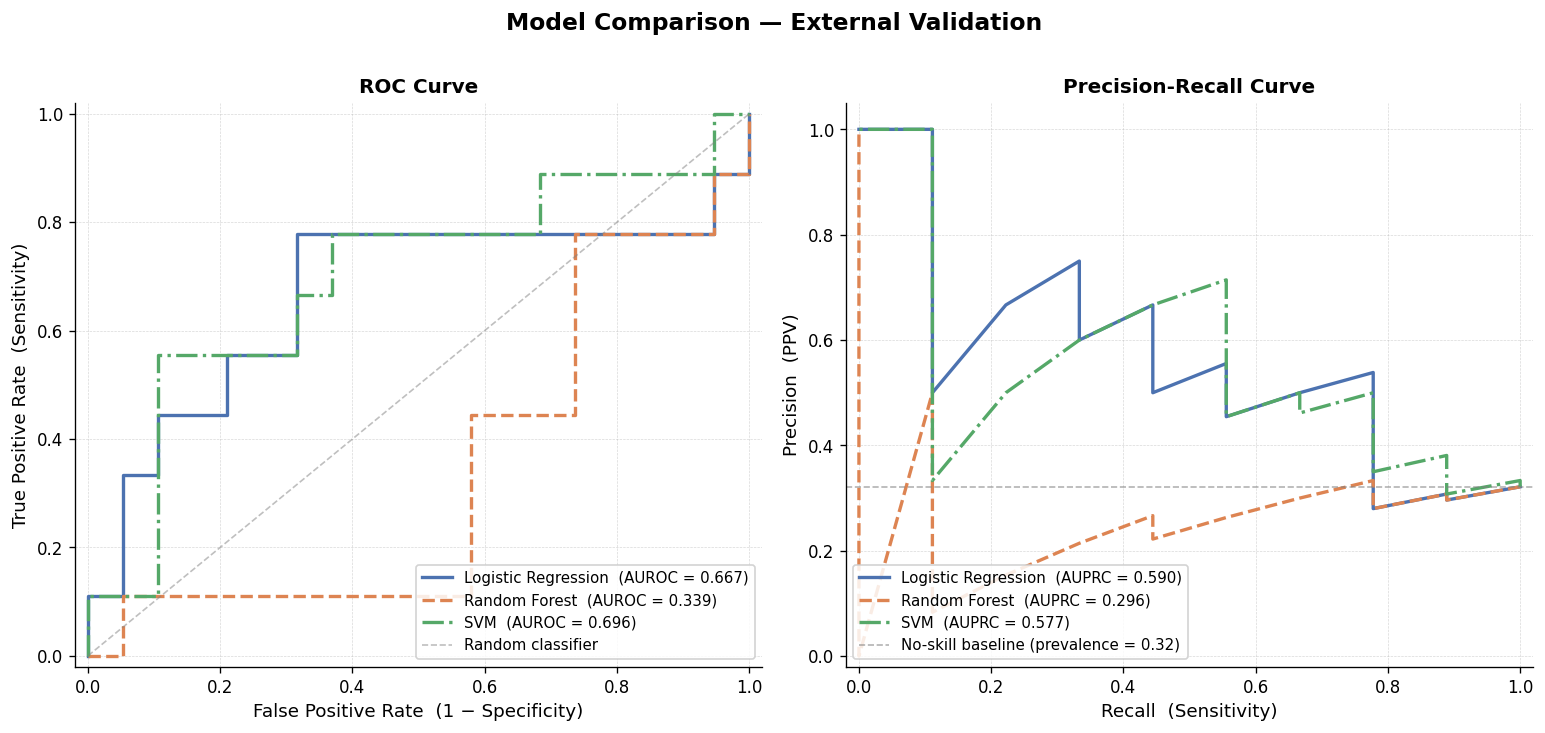

In [6]:
plot_roc_pr_comparison(
    models=[
        {"model_name": "Logistic Regression", "data":lgm_ext_pred},
        {"model_name": "Random Forest",                  "data": rf_ext_pred, "linestyle": "--"},
        {"model_name": "SVM",         "data": svm_ext_pred,  "linestyle": "-."},
    ],
    col_true="true_label",
    col_score="predicted_score",
    title="Model Comparison — External Validation",
)

### Part C2. Performance Summary, External Validation

##### Performance is reported at each model's Youden-optimized threshold, so these results represent each model's best attainable balance of sensitivity and specificity. Even at its optimal operating point, RF missed nearly all responders (sensitivity 0.111, F1 0.167) with  AUROC (0.339) and specificity (0.895), indicating that RF's probability scores for responders and non-responders overlap substantially, and no threshold can cleanly separate them. SVM achieved the best sensitivity (0.444) and F1 (0.533), and LR obtained (sensitivity 0.333, specificity 0.895, F1 0.429). These are genuine differences in how each model's decision boundary separates the two classes.
 
##### Key message: With thresholds already Youden-optimized, the performance gaps are true model differences. All three models performed exactly same when detecting non-responders. SVM is the most sensitive and balanced followed by LR. 

In [7]:
summary = performance_summary_table(pd.concat([rf_ext_met, lgm_ext_met,  svm_ext_met], ignore_index=True),
                          col_model="model",
                          metrics=["AUROC", "AUPRC", "sensitivity", "specificity", "F1"])

display(summary)

,AUROC,AUPRC,Sensitivity,Specificity,F1
model,,,,,
Random Forest,0.339000,0.296000,0.111000,0.895000,0.167000
LRM,0.667000,0.590000,0.333000,0.895000,0.429000
Linear SVM,0.696000,0.577000,0.444000,0.895000,0.533000


### Part C3. Confusion Matrix Comparison, External Validation (n = 28)

##### These matrices reflect each model's Youden-optimized threshold. RF identified only 1 of 9 responders (TP = 1, FN = 8) while correctly classifying 17 of 19 non-responders, confirming a fundamental score-separation problem rather than a calibration issue. LR recovered 3 responders with 2 false positives. SVM found 4 of 9 responders and generated 2 false positives. With only 9 true positives in the cohort, each individual prediction shifts sensitivity by ~11 percentage points, so all estimates carry wide uncertainty.
 
##### Key message: At the Youden-optimal threshold, RF still misses 8 of 9 responders, this is not a threshold artifact but a genuine model limitation. SVM is the most clinically useful model for responder identification. All counts should be interpreted cautiously given the small validation cohort.

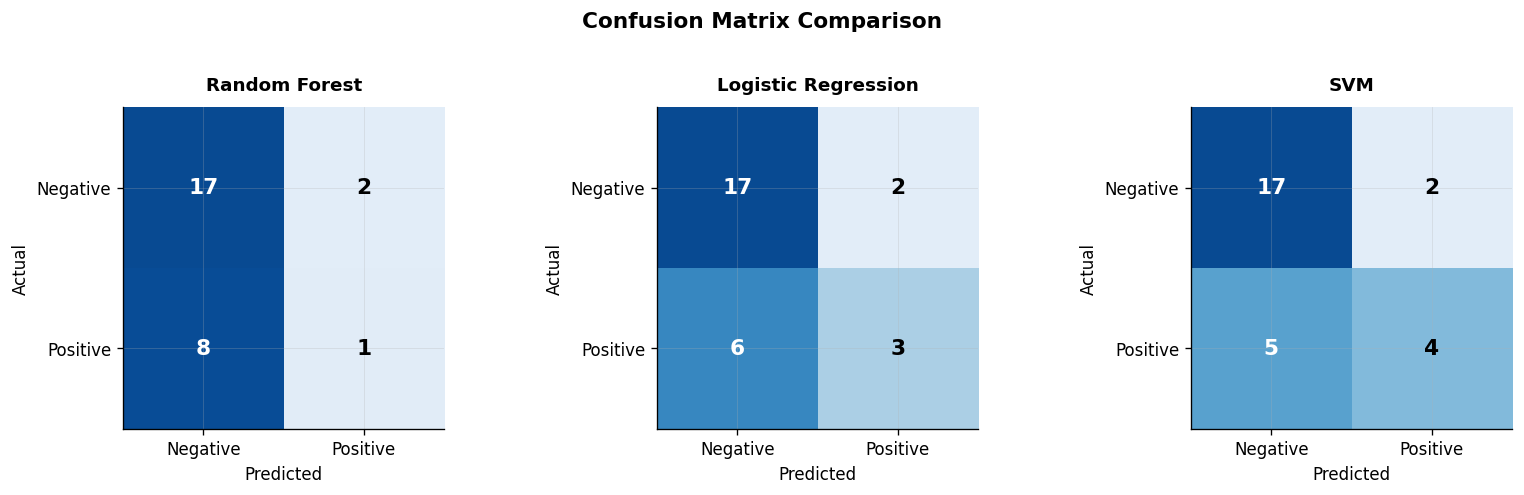

In [8]:
fig, axes = plot_confusion_matrices(
    models=[
        {"model_name": "Random Forest",         "data": rf_ext_pred},
        {"model_name": "Logistic Regression", "data": lgm_ext_pred},
        {"model_name": "SVM",                  "data": svm_ext_pred}

    ],
    class_names=["Negative", "Positive"],
    col_true="true_label",
    col_pred="predicted_label_optimized",
    title="Confusion Matrix Comparison",
)

# Conclusion

##### 1. The multi-feature signature generalizes across platforms. SVM and LR exceeded random chance on an independent microarray cohort (SVM AUROC 0.696 and LR AUROC 0.667), despite training on RNA-seq data. Z-score normalization effectively bridged the platform gap.
 
##### 2. BAP1 and PBRM1 are the key predictive features. Both chromatin remodeling genes consistently ranked as the strongest predictors in LR and SVM, consistent with published ccRCC immunotherapy biology. Immune microenvironment scores (stroma, myeloid inflammation, T-effector) provide complementary signal.
 
##### 3. 5-fold CV underestimates the true signal. Modest CV AUROCs (~0.54) reflect small training fold sizes, not an absence of learnable signal. Final models trained on the full cohort performed substantially better on external data.
 
##### 4. Model choice should match the clinical objective. Thresholds were Youden-optimized, so performance gaps are genuine. SVM has the best sensitivity and F1 (suited for identifying potential responders). RF's poor sensitivity even at its optimal threshold reflects true score-separation limitations.
 
##### 5. Key limitations. Small cohort sizes and the cross-platform design (RNA-seq training, microarray validation) are the primary constraints. Future priorities: larger prospective cohorts, within-platform validation.